In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)

from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")

experiment_df = pd.read_csv("simulated_ab_test_data.csv")

print("Dataset shape:", experiment_df.shape)
display(experiment_df.head())

Dataset shape: (12393, 15)


,user_id,total_interactions,unique_games,total_hours,total_purchases,log_total_hours,cluster,group,treatment,baseline_probability,treatment_uplift,conversion_probability,click_probability,clicked,converted
0,5250,27,21,225.5,21,5.422745,2,A,0,0.12,0.02,0.12,0.12,0,0
1,76767,56,36,1227.0,36,7.113142,2,B,1,0.12,0.02,0.14,0.16,0,0
2,86540,97,82,255.0,82,5.545177,2,B,1,0.12,0.02,0.14,0.16,0,0
3,103360,10,10,0.0,10,0.000000,0,B,1,0.05,0.02,0.07,0.16,1,1
4,144736,9,8,0.1,8,0.095310,0,A,0,0.05,0.02,0.05,0.12,0,0


#Our primary metric is purchase conversion rate.
- Null hypothesis (H₀): There is no difference in purchase conversion rates between Group A and Group B.
- Alternative hypothesis (H₁): There is a difference in purchase conversion rates between Group A and Group B.

In [49]:
ALPHA = 0.05

control = experiment_df[
    experiment_df["group"] == "A"
]

treatment = experiment_df[
    experiment_df["group"] == "B"
]

control_conversions = control["converted"].sum()
treatment_conversions = treatment["converted"].sum()

control_total = len(control)
treatment_total = len(treatment)

print("Control conversions:", control_conversions)
print("Treatment conversions:", treatment_conversions)

print("Control players:", control_total)
print("Treatment players:", treatment_total)

Control conversions: 421
Treatment conversions: 547
Control players: 6265
Treatment players: 6128


#Two-proportion Z-test

In [50]:
successes = np.array([
    control_conversions,
    treatment_conversions
])

sample_sizes = np.array([
    control_total,
    treatment_total
])

z_stat, p_value = proportions_ztest(
    count=successes,
    nobs=sample_sizes,
    alternative="two-sided"
)

print("Z-statistic:", round(z_stat, 4))
print("P-value:", p_value)

if p_value < ALPHA:
    print("Reject the null hypothesis.")
    print("The difference in conversion rates is statistically significant.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a conversion-rate difference.")

Z-statistic: -4.5764
P-value: 4.7313351562610225e-06
Reject the null hypothesis.
The difference in conversion rates is statistically significant.


In [51]:
ci_low, ci_high = confint_proportions_2indep(
    count1=treatment_conversions,
    nobs1=treatment_total,
    count2=control_conversions,
    nobs2=control_total,
    method="newcomb",
    compare="diff",
    alpha=ALPHA
)

observed_lift = (
    treatment_conversions / treatment_total
    - control_conversions / control_total
)

print("Observed absolute lift:", round(observed_lift * 100, 2), "percentage points")

print(
    "95% Confidence Interval:",
    round(ci_low * 100, 2),
    "to",
    round(ci_high * 100, 2),
    "percentage points"
)

Observed absolute lift: 2.21 percentage points
95% Confidence Interval: 1.26 to 3.16 percentage points


In [52]:
contingency_table = pd.crosstab(
    experiment_df["group"],
    experiment_df["converted"]
)

print("Contingency Table:")
display(contingency_table)

chi2_stat, chi2_p, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", round(chi2_stat, 4))
print("Degrees of freedom:", dof)
print("P-value:", chi2_p)

if chi2_p < ALPHA:
    print("Statistically significant association found.")
else:
    print("No statistically significant association found.")

Contingency Table:


converted,0,1
group,,
A,5844,421
B,5581,547


Chi-square statistic: 20.6378
Degrees of freedom: 1
P-value: 5.548980381008064e-06
Statistically significant association found.


In [53]:
np.random.seed(42)

N_BOOTSTRAPS = 10000

control_outcomes = control["converted"].values
treatment_outcomes = treatment["converted"].values

bootstrap_lifts = []

for _ in range(N_BOOTSTRAPS):

    sampled_control = np.random.choice(
        control_outcomes,
        size=len(control_outcomes),
        replace=True
    )

    sampled_treatment = np.random.choice(
        treatment_outcomes,
        size=len(treatment_outcomes),
        replace=True
    )

    lift = (
        sampled_treatment.mean()
        - sampled_control.mean()
    )

    bootstrap_lifts.append(lift)

bootstrap_lifts = np.array(bootstrap_lifts)

bootstrap_low, bootstrap_high = np.percentile(
    bootstrap_lifts,
    [2.5, 97.5]
)

print("Bootstrap 95% CI:")
print(
    round(bootstrap_low * 100, 2),
    "to",
    round(bootstrap_high * 100, 2),
    "percentage points"
)

Bootstrap 95% CI:
1.25 to 3.14 percentage points


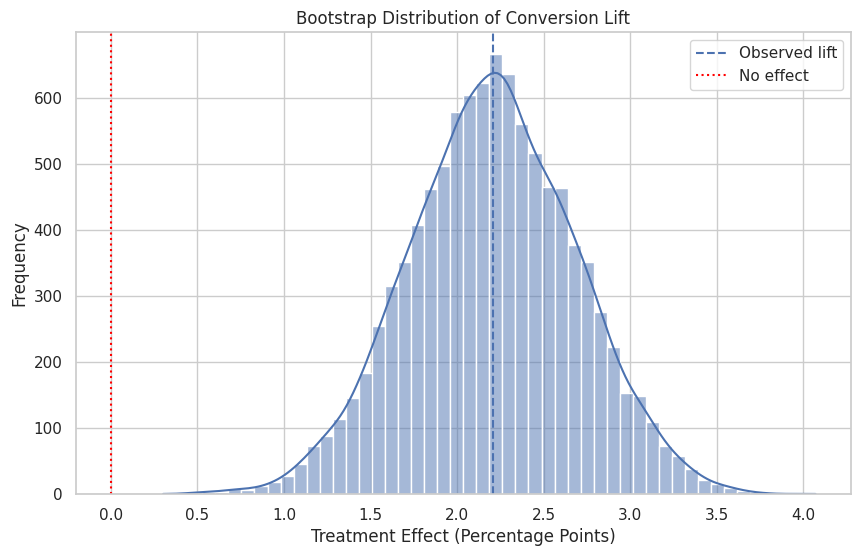

In [54]:
plt.figure(figsize=(10, 6))

sns.histplot(
    bootstrap_lifts * 100,
    bins=50,
    kde=True
)

plt.axvline(
    observed_lift * 100,
    linestyle="--",
    label="Observed lift"
)

plt.axvline(
    0,
    color="red",
    linestyle=":",
    label="No effect"
)

plt.title("Bootstrap Distribution of Conversion Lift")
plt.xlabel("Treatment Effect (Percentage Points)")
plt.ylabel("Frequency")

plt.legend()
plt.show()

In [55]:
control_clicks = control["clicked"].sum()
treatment_clicks = treatment["clicked"].sum()

ctr_successes = np.array([
    control_clicks,
    treatment_clicks
])

ctr_samples = np.array([
    control_total,
    treatment_total
])

ctr_z, ctr_p = proportions_ztest(
    ctr_successes,
    ctr_samples,
    alternative="two-sided"
)

control_ctr = control_clicks / control_total
treatment_ctr = treatment_clicks / treatment_total

print("Control CTR:", round(control_ctr * 100, 2), "%")
print("Treatment CTR:", round(treatment_ctr * 100, 2), "%")

print("CTR absolute lift:", round(
    (treatment_ctr - control_ctr) * 100, 2
), "percentage points")

print("CTR p-value:", ctr_p)

Control CTR: 11.96 %
Treatment CTR: 16.19 %
CTR absolute lift: 4.23 percentage points
CTR p-value: 1.2044688127642731e-11


In [56]:
summary = pd.DataFrame({
    "Metric": [
        "Purchase Conversion",
        "Click Through Rate"
    ],

    "Control": [
        control_ctr * 0 + control_conversions / control_total,
        control_ctr
    ],

    "Treatment": [
        treatment_conversions / treatment_total,
        treatment_ctr
    ],

    "Absolute Lift": [
        observed_lift,
        treatment_ctr - control_ctr
    ],

    "P-value": [
        p_value,
        ctr_p
    ]
})

summary["Control"] *= 100
summary["Treatment"] *= 100
summary["Absolute Lift"] *= 100

display(summary.round(4))

,Metric,Control,Treatment,Absolute Lift,P-value
0,Purchase Conversion,6.7199,8.9262,2.2064,0.0
1,Click Through Rate,11.9553,16.1880,4.2327,0.0


In [57]:
print("========== EXPERIMENT CONCLUSION ==========")

print(
    f"Control Conversion: {control_conversions/control_total*100:.2f}%"
)

print(
    f"Treatment Conversion: {treatment_conversions/treatment_total*100:.2f}%"
)

print(
    f"Absolute Lift: {observed_lift*100:.2f} percentage points"
)

print(f"P-value: {p_value:.6g}")

print(
    f"95% CI: [{ci_low*100:.2f}, {ci_high*100:.2f}] percentage points"
)

if p_value < ALPHA and ci_low > 0:
    print("\nDecision: Positive statistically significant result.")
else:
    print("\nDecision: No statistically significant positive result.")

========== EXPERIMENT CONCLUSION ==========
Control Conversion: 6.72%
Treatment Conversion: 8.93%
Absolute Lift: 2.21 percentage points
P-value: 4.73134e-06
95% CI: [1.26, 3.16] percentage points

Decision: Positive statistically significant result.


# ***conclusion***
The simulated A/B experiment evaluated personalized game recommendations against a generic recommendation strategy. The treatment group achieved a conversion rate of 8.93%, compared with 6.72% in the control group, representing an absolute improvement of 2.21 percentage points and a relative increase of 32.83%.

The difference was statistically significant (p = 0.000004731). The Newcombe 95% confidence interval ranged from 1.26 to 3.16 percentage points, while the bootstrap confidence interval ranged from 1.25 to 3.14 percentage points. Both methods produced highly consistent estimates.

The treatment group also demonstrated a 4.23 percentage-point improvement in click-through rate. These results indicate a positive treatment effect under the assumptions of the simulated experiment.